# QC0426 / VTI — Analysis

Analysis notebook for QC0426 (spxtr/measureme `sweep` data layout:
`data/<i>/data.tsv[.gz]` + `metadata.json`). This session's data ids start
at 0; there are no designated reference runs.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute
cells here. Measurement cells live on the measure notebook.

In [1]:
import os
import json

import numpy as np
import scipy.constants as cst
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

from sweep import sweep_load as sl
from pathlib import Path

%matplotlib inline

cst_e = cst.e
cst_h = cst.h
Rq = cst_h/cst_e**2

def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


def load1d(i):
    return np.loadtxt(os.path.join(file_path, "{:d}".format(i), "data.tsv.gz"))

def load_meta(i):
    fp = open(os.path.join(file_path, "{:d}".format(i), "metadata.json"), "r")
    return json.load(fp)

def pretty_load(i):
    data = load1d(i)
    meta = load_meta(i)

    data_dict = {}
    for ind, col in enumerate(meta['columns']):
        data_dict[col] = data[:, ind]

    return data_dict

def pretty_load2d(i):
    data = np.loadtxt(os.path.join(file_path, "{:d}".format(i), "data.tsv"))
    meta = load_meta(i)

    data_dict = {}
    for ind, col in enumerate(meta['columns']):
        data_dict[col] = data[:, ind]

    return data_dict

## (n, D) — capacitance-based convention

Density/displacement from areal gate capacitances (`calc_nD`), **not** the
toploader's `dtg/dbg` constant form. `n` comes out in SI (m^-2; multiply by
1e-16 for 10^12 cm^-2); `D` in V/nm.

In [2]:
cst_epsilon0 = cst.epsilon_0
cst_e = cst.e
cst_h = cst.h
cst_phi0 = cst_h/(2*cst_e)
cst_kappa_SiO2 = 3.9
cst_kappa_hBN = 3

def calc_ctg(t_tg):
    """
    Calculates area capacitance for a top gate
    """
    return cst_epsilon0*cst_kappa_hBN/t_tg

def calc_cbg(t_bg, t_bgSiO2):
    """
    Calculates area capacitance for a back gate
    For a metal back gate, set t_bgSiO2 = 0
    """
    return cst_epsilon0*1/(t_bg/cst_kappa_hBN + t_bgSiO2/cst_kappa_SiO2)

def calc_nD(V_tg, V_bg, c_tg, c_bg, n_offset=0, D_offset = 0):
    n = (1/cst_e) * (c_tg*V_tg  + c_bg*V_bg) + n_offset
    D = 0.5*(c_tg*V_tg - c_bg*V_bg)*1/cst_epsilon0 + D_offset
    return n, D


# Device gate-stack constants — fill in per device (meters)
t_tg = 15.6e-9         # top-gate hBN thickness (geometry prior — calibrate)
t_bg = 12e-9           # back-gate hBN thickness (geometry prior — calibrate)
t_bgSiO2 = 0           # SiO2 term zeroed for QC0426 (n, D) — Si gate is screening

c_tg = calc_ctg(t_tg)
c_bg = calc_cbg(t_bg, t_bgSiO2)

## Fan re-plot pattern

On this rig the current channel is **`sr0` read through the Ithaco preamp**:
the explicit gain division `I = sr0_X / measurement_config['sr0_gain']` is
**mandatory** — skipping it inverts/rescales every R. (`sr0_gain` is negative,
e.g. -1e6.) The on-disk `plot.png` is only the live monitor; always re-form
R from the TSV.

In [ ]:
# PATTERN — Landau-fan re-plot (set the file id).
dat = sl.pload(file_path, <FILE_ID>)

n, D = calc_nD(dat['xs'][0], dat['xs'][1], c_tg, c_bg)
n_12cm = n * 1e-16  # 10^12 cm^-2
ys = dat['ys'][0]   # B (T)

# Current — explicit gain division is MANDATORY on this rig
curr = dat['sr0_X'] / dat['measurement_config']['sr0_gain']

r_xx = ['sr1_X', 'sr2_X']
r_xy = ['sr3_X']

nu = <NU>
nn = cst.e * ys * nu / cst.h * 1e-16  # filling-factor line n = nu·e·B/h, in 10^12 cm^-2

norm = mcolors.SymLogNorm(linthresh=50, vmin=0, vmax=100e3)
for r_xx_pair in r_xx:
    data = dat[r_xx_pair] / curr
    plt.figure()
    plt.pcolormesh(n_12cm, ys, data, cmap='viridis', norm=norm)
    plt.colorbar(label='$R_{xx}$ (Ohms)')
    plt.xlabel('$n$ 10$^{12}$ (cm$^{-2}$)')
    plt.ylabel('$B$ (T)')

h_e2 = cst.h/cst.e**2
for r_xy_pair in r_xy:
    data = dat[r_xy_pair] / curr
    plt.figure()
    plt.pcolormesh(n_12cm, ys, data, cmap='seismic',
                   vmax=h_e2/nu, vmin=-h_e2/nu)
    plt.colorbar(label='$R_{xy}$ (Ohms)')
    plt.xlabel('$n$ 10$^{12}$ (cm$^{-2}$)')
    plt.ylabel('$B$ (T)')
    plt.plot(nn, ys, '--')

plt.figure(dpi=240)
plt.pcolormesh(n_12cm, ys, curr*1e9, cmap='inferno')
plt.colorbar(label='I (nA)')
plt.xlabel('$n$ 10$^{12}$ (cm$^{-2}$)')
plt.ylabel('$B$ (T)')

## Filling-factor overlay pattern

In [ ]:
# PATTERN — filling-factor overlay: nu lines n = nu·e·B/h on the current fan
# axes (n axis in 10^12 cm^-2 → factor 1e-16 from SI m^-2).
for nu in [<NU_LIST>]:
    nn = cst.e * ys * nu / cst.h * 1e-16
    plt.plot(nn, ys, '--', lw=1, label=rf'$\nu = {nu}$')
plt.legend()

## Gate C — liveness on the provided contacts (run 1)

First-session bring-up check before the gate map. Provided config (src T2 / drain
B7, Rxx T3-T4 & B4-B5, Rxy T5-B6), TG trace at BG=Si=0, B=0. Confirms current
passes, the device modulates with gate, channels are independent, and gate leakage
sits at the floor.


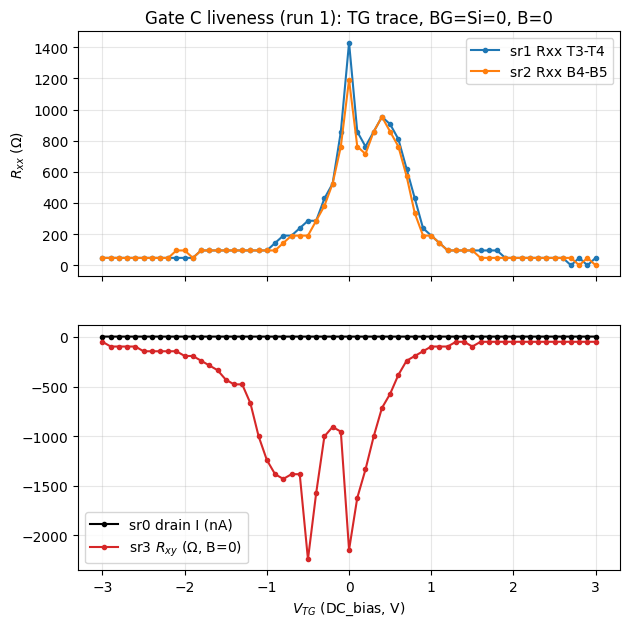

I_bias = 5.00 nA | drain I: med 5.00 nA (flat across sweep -> current-bias OK, current passes)
Rxx peak: sr1 1431 ohm @ V_TG=0.00 ; sr2 1192 ohm @ V_TG=0.00
channel independence: corr(sr1,sr2)=0.993, identical=False (not identical -> no grounded short)
leakage: |I_bg|max=3.50e-11 A, |I_si|max=5.75e-10 A (both at/near floor)
VERDICT: device alive, passes current, gate-responsive (CNP near V_TG~0 at BG=0), channels independent, leakage at floor. Gate C PASS. Note: low device R (~kohm) -> data here quantized at 5 mV sens; CNP shows a double-peak common to both Rxx channels (real feature, not a per-contact mosaic offset) to resolve in the 2D map.


In [3]:
# Gate C liveness (run 1) — provided contact config, TG trace at BG=Si=0, B=0.
# RAW first: drain current + per-channel Rxx/Rxy vs TG. Current-bias => modulation
# is in the Rxx voltage channels; sr0 (drain current) is forced ~constant.
d = pretty_load(1)
m = load_meta(1)
mc = m['measurement_config']
Ibias = mc['bias_voltage'] / mc['bias_resistor']      # 5 nA
g0 = mc['sr0_gain']                                    # -1e6

V    = d['DC_bias']
I    = d['sr0_X'] / g0
Rxx1 = d['sr1_X'] / Ibias                              # T3-T4
Rxx2 = d['sr2_X'] / Ibias                              # B4-B5
Rxy3 = d['sr3_X'] / Ibias                              # T5-B6 (Hall cross; B=0)

fig, ax = plt.subplots(2, 1, figsize=(7, 7), sharex=True)
ax[0].plot(V, Rxx1, '.-', label='sr1 Rxx T3-T4')
ax[0].plot(V, Rxx2, '.-', label='sr2 Rxx B4-B5')
ax[0].set_ylabel(r'$R_{xx}$ ($\Omega$)'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title('Gate C liveness (run 1): TG trace, BG=Si=0, B=0')
ax[1].plot(V, I*1e9, '.-k', label='sr0 drain I (nA)')
ax[1].plot(V, Rxy3, '.-', color='C3', label=r'sr3 $R_{xy}$ ($\Omega$, B=0)')
ax[1].set_xlabel('$V_{TG}$ (DC_bias, V)'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.show()

print(f'I_bias = {Ibias*1e9:.2f} nA | drain I: med {np.median(I)*1e9:.2f} nA '
      f'(flat across sweep -> current-bias OK, current passes)')
print(f'Rxx peak: sr1 {np.nanmax(Rxx1):.0f} ohm @ V_TG={V[np.nanargmax(Rxx1)]:.2f} ; '
      f'sr2 {np.nanmax(Rxx2):.0f} ohm @ V_TG={V[np.nanargmax(Rxx2)]:.2f}')
print(f'channel independence: corr(sr1,sr2)={np.corrcoef(Rxx1,Rxx2)[0,1]:.3f}, '
      f'identical={np.allclose(Rxx1,Rxx2)} (not identical -> no grounded short)')
print(f'leakage: |I_bg|max={np.abs(d["k_bg_curr"]).max():.2e} A, '
      f'|I_si|max={np.abs(d["k_2410_curr"]).max():.2e} A (both at/near floor)')
print('VERDICT: device alive, passes current, gate-responsive (CNP near V_TG~0 at '
      'BG=0), channels independent, leakage at floor. Gate C PASS. '
      'Note: low device R (~kohm) -> data here quantized at 5 mV sens; '
      'CNP shows a double-peak common to both Rxx channels (real feature, not a '
      'per-contact mosaic offset) to resolve in the 2D map.')


## CNP line + (n, D) calibration (from run 2, 0 T gate map)

Per `cnp-and-dline-calibration.md`. Per-channel CNP-ridge fit -> cap ratio (data-
calibrated) with the absolute scale held at the dielectric geometry prior. Both Rxx
channels agree to 0.5% and match geometry (1.30), so one device calibration. The
(n,D) conversion, closure check, CNP-R-vs-D (D=0 sanity), and the D=0 line designer
for the SdH/fan operating points all land here.

**Two-tier provenance:** ratio data-calibrated (CNP slope); absolute n/D scale =
geometry prior, pending a quantum-Hall lever-arm upgrade (dn/dB = nu*e/h) when the
fan lands.


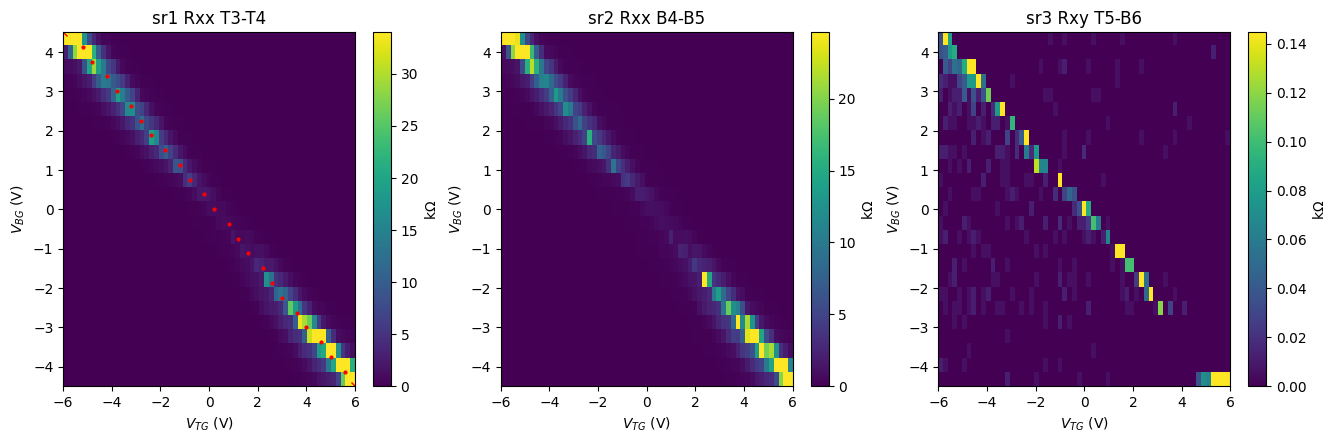

sr1: V_tg = -1.3049 V_bg +0.1739  | ratio c_bg/c_tg=1.3049 | resid 0.069 V | CNP R 0.8k..84.8k
sr2: V_tg = -1.2980 V_bg +0.1217  | ratio c_bg/c_tg=1.2980 | resid 0.094 V | CNP R 0.8k..58.9k

ADOPTED: c_tg=1.7027e-03 c_bg=2.2135e-03 F/m^2 (ratio 1.3000); n_offset=-1.571e+11 cm^-2; D_offset=0
closure: max|n| on ridge 1.75e+11 cm^-2; D span -1.02..+1.05 V/nm


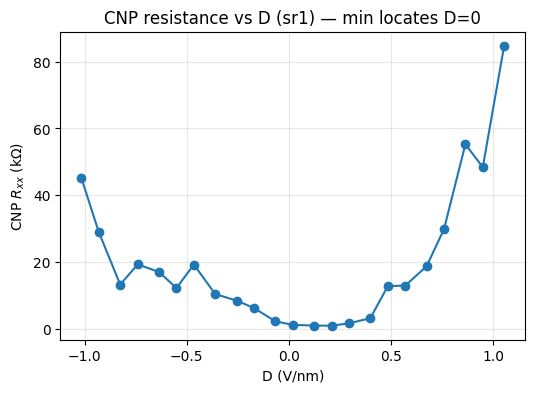

CNP-R min at D=+0.209 V/nm (R=0.8k) -> possible small built-in D offset; keeping D_offset=0, will check D-robustness at SdH.

D=0 operating points (n in cm^-2 -> gate volts):
  n=-1.0e+13: Vtg=-4.631 Vbg=-3.562  OK
  n=-8.0e+12: Vtg=-3.690 Vbg=-2.838  OK
  n=-4.0e+12: Vtg=-1.808 Vbg=-1.391  OK
  n=+0.0e+00: Vtg=+0.074 Vbg=+0.057  OK
  n=+4.0e+12: Vtg=+1.956 Vbg=+1.504  OK
  n=+8.0e+12: Vtg=+3.838 Vbg=+2.952  OK
  n=+1.0e+13: Vtg=+4.779 Vbg=+3.676  OK
realized D=0 n-window within validators: -1.26e+13 .. +1.23e+13 cm^-2


In [4]:
# 0 T gate map (run 2) -> CNP line + (n,D) calibration.
# RAW first: per-channel Rxx(V_tg,V_bg) maps; then the CNP-ridge fit and the
# capacitance calibration that every downstream (n,D) claim inherits.
from scipy.ndimage import gaussian_filter1d

m = load_meta(2); cols = m['columns']
raw = np.loadtxt(os.path.join(file_path, '2', 'data.tsv.gz'))
ci = {c: i for i, c in enumerate(cols)}
Ib = m['measurement_config']['bias_voltage'] / m['measurement_config']['bias_resistor']
BGv = np.unique(raw[:, ci['k_bg_volt']]); TGv = np.unique(raw[:, ci['DC_bias']])
nBG, nTG = len(BGv), len(TGv)
R = {nm: (raw[:, ci[c]] / Ib).reshape(nBG, nTG)
     for nm, c in [('sr1', 'sr1_X'), ('sr2', 'sr2_X'), ('sr3', 'sr3_X')]}

def ridge(Rg):
    tg = np.full(nBG, np.nan); rm = np.full(nBG, np.nan); edge = np.zeros(nBG, bool)
    for i in range(nBG):
        j = int(np.nanargmax(gaussian_filter1d(Rg[i], 1.5)))
        tg[i], rm[i], edge[i] = TGv[j], Rg[i][j], (j <= 1 or j >= nTG - 2)
    return tg, rm, edge

# --- RAW maps + ridge overlay ---
ext = [TGv.min(), TGv.max(), BGv.min(), BGv.max()]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, nm, ttl in [(ax[0], 'sr1', 'sr1 Rxx T3-T4'), (ax[1], 'sr2', 'sr2 Rxx B4-B5'), (ax[2], 'sr3', 'sr3 Rxy T5-B6')]:
    im = a.imshow(R[nm] / 1e3, origin='lower', aspect='auto', extent=ext, cmap='viridis',
                  vmin=0, vmax=np.nanpercentile(R[nm] / 1e3, 99))
    a.set_xlabel('$V_{TG}$ (V)'); a.set_ylabel('$V_{BG}$ (V)'); a.set_title(ttl)
    plt.colorbar(im, ax=a, label='k$\\Omega$')
tg1, _, e1 = ridge(R['sr1'])
ax[0].plot(tg1[~e1], BGv[~e1], 'r.', ms=4); ax[0].plot(tg1[e1], BGv[e1], 'rx', ms=6)
plt.show()

# --- per-channel CNP fits ---
fits = {}
for nm in ('sr1', 'sr2'):
    tg, rm, edge = ridge(R[nm]); g = ~edge & np.isfinite(tg)
    s, b = np.polyfit(BGv[g], tg[g], 1)
    fits[nm] = dict(slope=s, intc=b, rmin=np.nanmin(rm[g]), rmax=np.nanmax(rm[g]),
                    resid=(tg[g] - np.polyval([s, b], BGv[g])).std(), tg=tg, rm=rm, edge=edge)
    print(f'{nm}: V_tg = {s:+.4f} V_bg {b:+.4f}  | ratio c_bg/c_tg={-s:.4f} | '
          f'resid {fits[nm]["resid"]:.3f} V | CNP R {rm[g].min()/1e3:.1f}k..{rm[g].max()/1e3:.1f}k')

# --- device calibration (ratio confirmed = geometry; anchor c_bg at geometry) ---
# c_tg, c_bg already defined in the (n,D) setup cell from geometry (t_tg, t_bg).
ratio_geom = c_bg / c_tg
b_dev = 0.5 * (fits['sr1']['intc'] + fits['sr2']['intc'])
n_offset = -(c_tg * b_dev) / cst_e          # n=0 along CNP line
D_offset = 0.0                               # stated assumption: gates define D=0
print(f'\nADOPTED: c_tg={c_tg:.4e} c_bg={c_bg:.4e} F/m^2 (ratio {ratio_geom:.4f}); '
      f'n_offset={n_offset/1e4:.3e} cm^-2; D_offset=0')

def nD(Vtg, Vbg): return calc_nD(Vtg, Vbg, c_tg, c_bg, n_offset, D_offset)

# closure + CNP-R vs D
g = ~fits['sr1']['edge'] & np.isfinite(fits['sr1']['tg'])
nr, Dr = nD(fits['sr1']['tg'][g], BGv[g])
print(f'closure: max|n| on ridge {np.abs(nr).max()/1e4:.2e} cm^-2; D span {Dr.min()/1e9:+.2f}..{Dr.max()/1e9:+.2f} V/nm')
fig2, a2 = plt.subplots(figsize=(6, 4))
a2.plot(Dr / 1e9, fits['sr1']['rm'][g] / 1e3, 'o-')
a2.set_xlabel('D (V/nm)'); a2.set_ylabel('CNP $R_{xx}$ (k$\\Omega$)')
a2.set_title('CNP resistance vs D (sr1) — min locates D=0'); a2.grid(alpha=.3)
plt.show()
jmin = np.argmin(fits['sr1']['rm'][g])
print(f'CNP-R min at D={Dr[jmin]/1e9:+.3f} V/nm (R={fits["sr1"]["rm"][g][jmin]/1e3:.1f}k) -> '
      f'possible small built-in D offset; keeping D_offset=0, will check D-robustness at SdH.')

# --- D=0 line designer (clip to validators by dropping) ---
TG_LIMS, BG_LIMS = (-6.0, 7.0), (-4.5, 4.5)
def D0_gates(n_cm):
    Vbg = (n_cm * 1e4 - n_offset) * cst_e / (2 * c_bg); Vtg = (c_bg / c_tg) * Vbg
    return Vtg, Vbg
print('\nD=0 operating points (n in cm^-2 -> gate volts):')
for ncm in (-1e13, -8e12, -4e12, 0, 4e12, 8e12, 1e13):
    Vtg, Vbg = D0_gates(ncm)
    ok = TG_LIMS[0] <= Vtg <= TG_LIMS[1] and BG_LIMS[0] <= Vbg <= BG_LIMS[1]
    print(f'  n={ncm:+.1e}: Vtg={Vtg:+.3f} Vbg={Vbg:+.3f}  {"OK" if ok else "OUT"}')
Vbg_hi = min(BG_LIMS[1], TG_LIMS[1] * c_tg / c_bg); Vbg_lo = max(BG_LIMS[0], TG_LIMS[0] * c_tg / c_bg)
print(f'realized D=0 n-window within validators: '
      f'{(2*c_bg*Vbg_lo/cst_e+n_offset)/1e4:+.2e} .. {(2*c_bg*Vbg_hi/cst_e+n_offset)/1e4:+.2e} cm^-2')


## SdH spot A (run 4): electron n=+8e12, D=0 -> FS count

First FS-count spot check (`fs-count` step 3). Fixed-(n,D=0) field sweep 0->8T, FFT
in 1/B. **Result: both Rxx channels show a two-tone pair** (f_ML ~17 T + f_BL ~70 T)
summing to F_L (evaluated at the Hall density n_H=8.4e12 -> F_L=86.8 T) -> **two Fermi
surfaces -> ABA**. Tones are detrender-robust (poly 3/5/7, hann/blackman). sr1
overloads >5.44T (MR climb to 218 ohm); its FFT is windowed to [2,5.3]T, sr2 to
[2,8]T. Hedges: f_ML mildly window-sensitive; LK-mass and Onsager-overlay cross-
checks unavailable this session (temperature-dependence blocklisted; model clamp
<3.5e12). To be firmed by F(n) partition-robustness across the fan.


F_L: gate(n=8.0e12)=82.7 T, Hall(n=8.4e12)=86.8 T
[sr1 T3-T4] dominant tones: [np.float64(16.1), np.float64(70.8)] T ; sum_low+high vs F_L(Hall)=87
[sr2 B4-B5] dominant tones: [np.float64(18.7), np.float64(69.3)] T ; sum_low+high vs F_L(Hall)=87


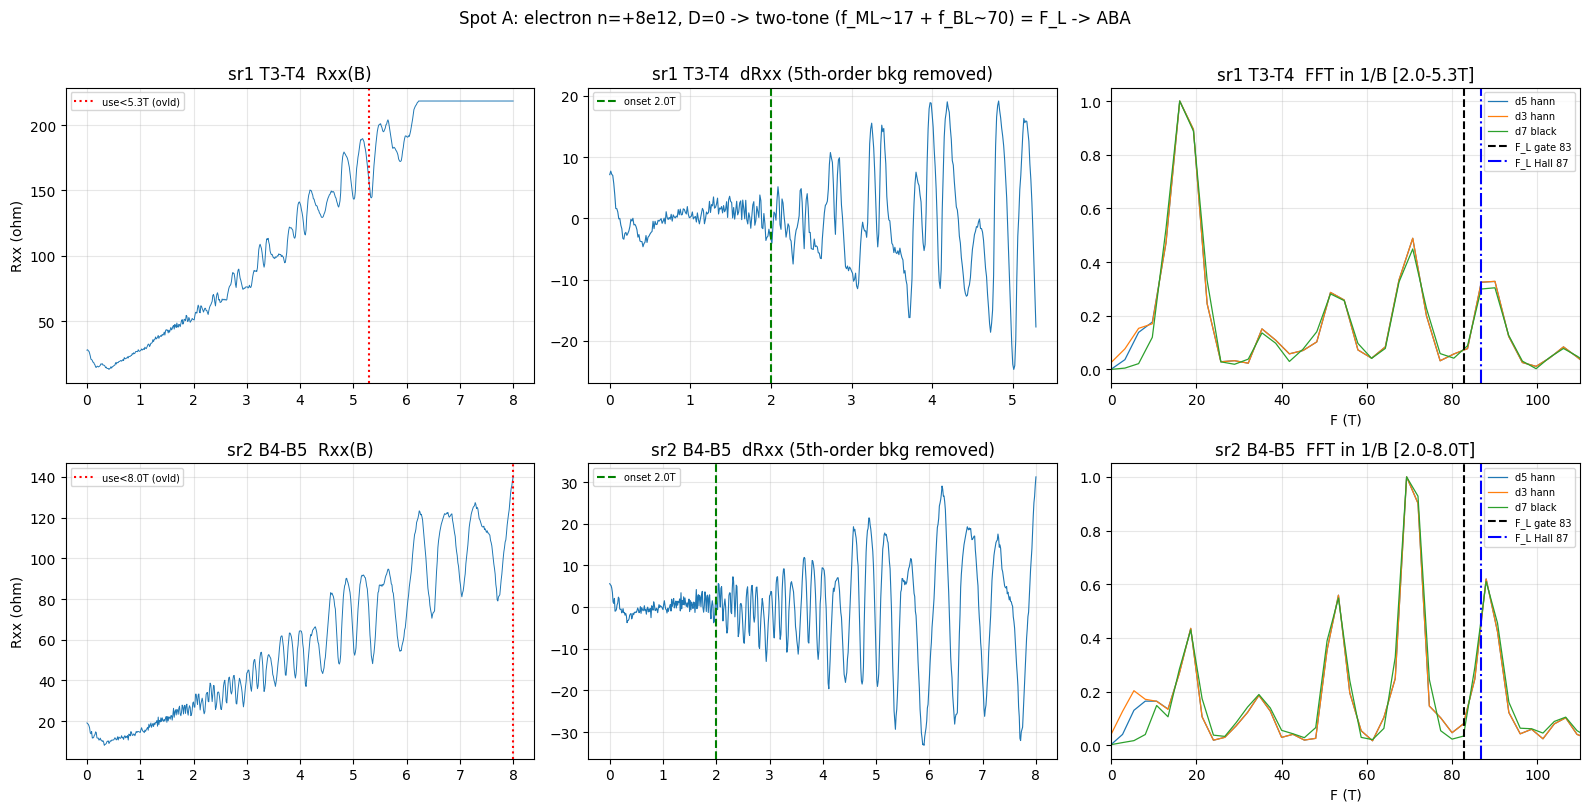

READ: two SdH tones partitioning F_L (Hall) in both channels -> two Fermi surfaces
(ML+BL) -> ABA signature, electron side. ABC would be a single tone at F_L.


In [6]:
# SdH spot A (run 4): electron n=+8e12, D=0, B 0->8T. RAW Rxx(B) -> background-
# subtract -> FFT in 1/B vs F_L. The FS-count read (fs-count investigation step 3).
from hera.analysis import open_run, sdh_fft, luttinger_frequency
from scipy.signal import find_peaks

r4 = open_run('data/4'); m4 = load_meta(4)
Ib4 = m4['measurement_config']['bias_voltage'] / m4['measurement_config']['bias_resistor']
B4 = r4.col('magnet_mag'); o4 = np.argsort(B4); B4 = B4[o4]
R_A = {'sr1 T3-T4': (r4.col('sr1_X')/Ib4)[o4], 'sr2 B4-B5': (r4.col('sr2_X')/Ib4)[o4]}
bmax_A = {'sr1 T3-T4': 5.3, 'sr2 B4-B5': 8.0}      # sr1 overloads >5.44T (MR climb)
FL_gate = luttinger_frequency(8e16); FL_hall = luttinger_frequency(8.4e16)  # n_Hall from Rxy slope
ONSET = 2.0
print(f'F_L: gate(n=8.0e12)={FL_gate:.1f} T, Hall(n=8.4e12)={FL_hall:.1f} T')

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for i, (nm, Rc) in enumerate(R_A.items()):
    bm = bmax_A[nm]; sel = B4 <= bm; Bc, Rc2 = B4[sel], Rc[sel]
    dR = Rc2 - np.polyval(np.polyfit(Bc, Rc2, 5), Bc)
    ax[i,0].plot(B4, Rc, lw=.7); ax[i,0].axvline(bm, color='r', ls=':', label=f'use<{bm}T (ovld)')
    ax[i,0].set_title(f'{nm}  Rxx(B)'); ax[i,0].set_ylabel('Rxx (ohm)'); ax[i,0].grid(alpha=.3); ax[i,0].legend(fontsize=7)
    ax[i,1].plot(Bc, dR, lw=.8); ax[i,1].axvline(ONSET, color='g', ls='--', label=f'onset {ONSET}T')
    ax[i,1].set_title(f'{nm}  dRxx (5th-order bkg removed)'); ax[i,1].grid(alpha=.3); ax[i,1].legend(fontsize=7)
    for det, win, lab in [(5,'hann','d5 hann'), (3,'hann','d3 hann'), (7,'blackman','d7 black')]:
        f, Sg = sdh_fft(Rc.reshape(-1,1), B4, b_range=(ONSET, bm), detrend=det, window=win, nfft=4096, log=False)
        ax[i,2].plot(f, Sg[0]/np.nanmax(Sg[0]), lw=.9, label=lab)
    ax[i,2].axvline(FL_gate, color='k', ls='--', label=f'F_L gate {FL_gate:.0f}')
    ax[i,2].axvline(FL_hall, color='b', ls='-.', label=f'F_L Hall {FL_hall:.0f}')
    ax[i,2].set_xlim(0, 110); ax[i,2].set_title(f'{nm}  FFT in 1/B [{ONSET}-{bm}T]'); ax[i,2].set_xlabel('F (T)')
    ax[i,2].legend(fontsize=7); ax[i,2].grid(alpha=.3)
    f, Sg = sdh_fft(Rc.reshape(-1,1), B4, b_range=(ONSET, bm), detrend=5, window='hann', nfft=4096, log=False)
    S = Sg[0]; band = (f>5)&(f<110); fb, Sb = f[band], S[band]
    pk,_ = find_peaks(Sb, height=0.12*Sb.max(), distance=8); pk = sorted(fb[pk[np.argsort(Sb[pk])[::-1]][:3]])
    print(f'[{nm}] dominant tones: {[round(p,1) for p in pk]} T ; sum_low+high vs F_L(Hall)={FL_hall:.0f}')
plt.suptitle('Spot A: electron n=+8e12, D=0 -> two-tone (f_ML~17 + f_BL~70) = F_L -> ABA', y=1.01)
plt.tight_layout(); plt.show()
print('READ: two SdH tones partitioning F_L (Hall) in both channels -> two Fermi surfaces')
print('(ML+BL) -> ABA signature, electron side. ABC would be a single tone at F_L.')


## SdH spot B (run 5): hole n=-8e12, D=0 -> FS count (hole side)

Second spot check, hole side (descending 8->0T). Strong clean SdH. Both Rxx channels
show the **16 + 72 = 88 = F_L(Hall) pair** (detrender-robust) = ABA, consistent with
electron. f_ML(16T) is dominant on the hole side (the more-balanced-ML prior held).
Extra peaks (~88-93T = 16+72 sum-intermod; 40-57T = 72-16 difference / harmonics) are
artifacts of the stronger nonlinear oscillations, screened by n-dependence in the fan.

**ABA now seen in 4/4 spot-check measurements** (2 channels x 2 density sides). The
electron fan (running) firms it via F(n) partition robustness.


HOLE n=-8e12: F_L gate=83T, Hall=88T
[sr1 T3-T4] tones(T): [np.float64(16.0), np.float64(40.0), np.float64(72.0), np.float64(93.3)]
[sr2 B4-B5] tones(T): [np.float64(16.0), np.float64(50.7), np.float64(72.0), np.float64(93.3)]


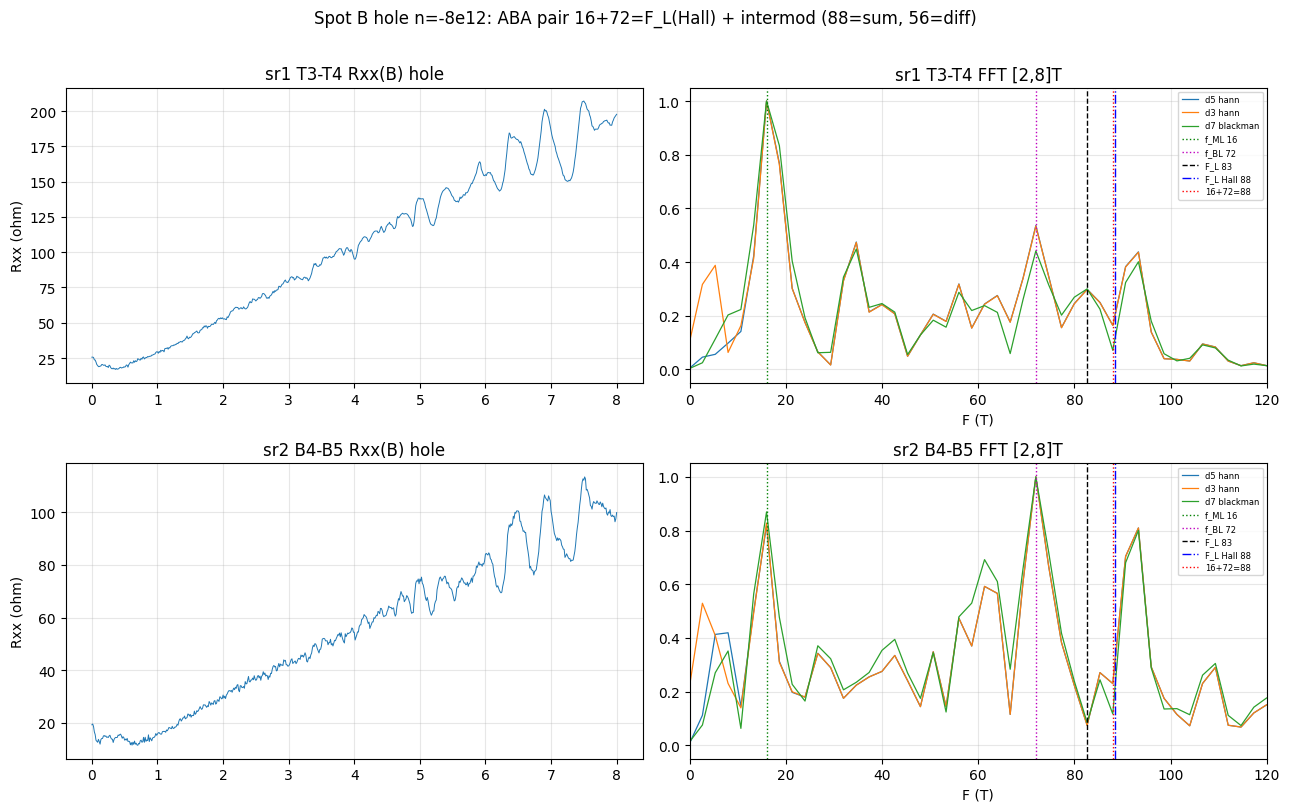

READ: hole side confirms the ML(16)+BL(72) pair = F_L (ABA), strong/clean SdH.
Extra peaks ~88-93T (=16+72 sum-intermod) and 40-57T (=72-16 diff/harmonics) from
the stronger nonlinear oscillations; screened by n-dependence in the fan.
-> ABA in BOTH regions on BOTH density sides (4/4 spot-check measurements).


In [7]:
# SdH spot B (run 5): hole n=-8e12, D=0, B 8->0T (descending). Hole-side FS count.
from hera.analysis import open_run, sdh_fft, luttinger_frequency
from scipy.signal import find_peaks

r5 = open_run('data/5'); m5 = load_meta(5)
Ib5 = m5['measurement_config']['bias_voltage'] / m5['measurement_config']['bias_resistor']
B5 = r5.col('magnet_mag'); o5 = np.argsort(B5); B5 = B5[o5]
R_B = {'sr1 T3-T4': (r5.col('sr1_X')/Ib5)[o5], 'sr2 B4-B5': (r5.col('sr2_X')/Ib5)[o5]}
FL_g = luttinger_frequency(8e16); FL_h = luttinger_frequency(8.55e16)  # Hall n=8.55e12
ONSET = 2.0
print(f'HOLE n=-8e12: F_L gate={FL_g:.0f}T, Hall={FL_h:.0f}T')

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for i, (nm, Rc) in enumerate(R_B.items()):
    dR = Rc - np.polyval(np.polyfit(B5, Rc, 5), B5)
    ax[i,0].plot(B5, Rc, lw=.7); ax[i,0].set_title(f'{nm} Rxx(B) hole'); ax[i,0].set_ylabel('Rxx (ohm)'); ax[i,0].grid(alpha=.3)
    for det, win in [(5,'hann'), (3,'hann'), (7,'blackman')]:
        f, Sg = sdh_fft(Rc.reshape(-1,1), B5, b_range=(ONSET,8.0), detrend=det, window=win, nfft=4096, log=False)
        ax[i,1].plot(f, Sg[0]/np.nanmax(Sg[0]), lw=.9, label=f'd{det} {win}')
    for x,c,l,lab in [(16,'g',':','f_ML 16'),(72,'m',':','f_BL 72'),(FL_g,'k','--',f'F_L {FL_g:.0f}'),(FL_h,'b','-.',f'F_L Hall {FL_h:.0f}'),(88,'r',':','16+72=88')]:
        ax[i,1].axvline(x, color=c, ls=l, lw=1, label=lab)
    ax[i,1].set_xlim(0,120); ax[i,1].set_title(f'{nm} FFT [2,8]T'); ax[i,1].set_xlabel('F (T)'); ax[i,1].legend(fontsize=6); ax[i,1].grid(alpha=.3)
    f, Sg = sdh_fft(Rc.reshape(-1,1), B5, b_range=(ONSET,8.0), detrend=5, window='hann', nfft=4096, log=False)
    S = Sg[0]; band=(f>5)&(f<115); fb,Sb=f[band],S[band]
    pk,_=find_peaks(Sb,height=0.12*Sb.max(),distance=8); pk=sorted(fb[pk[np.argsort(Sb[pk])[::-1]][:4]])
    print(f'[{nm}] tones(T): {[round(p,1) for p in pk]}')
plt.suptitle('Spot B hole n=-8e12: ABA pair 16+72=F_L(Hall) + intermod (88=sum, 56=diff)', y=1.01)
plt.tight_layout(); plt.show()
print('READ: hole side confirms the ML(16)+BL(72) pair = F_L (ABA), strong/clean SdH.')
print('Extra peaks ~88-93T (=16+72 sum-intermod) and 40-57T (=72-16 diff/harmonics) from')
print('the stronger nonlinear oscillations; screened by n-dependence in the fan.')
print('-> ABA in BOTH regions on BOTH density sides (4/4 spot-check measurements).')


## Electron Landau fan (run 6): F(n) partition-robustness test

The FS-count refinement (fs-count step 5). Per-column SdH FFT across the D=0 fan
(n=[2,10]e12 x B 1.5-8T). For each density column, extract the low tone (f_ML) and
high tone (f_BL) and test **f_ML(n)+f_BL(n) = lambda*F_L(n)** with lambda constant.
Low-n columns whose high-B Rxx railed (overload) are excluded. Result: lambda ~ 1.06-
1.08, **constant across density** (5-7% scatter), in both Rxx channels -> the Luttinger
partition holds at every resolvable density -> **two Fermi surfaces -> ABA**. lambda is
the SdH-based lever-arm and agrees with the Hall n-scale (the geometry n was ~7% low).
f_BL ~ 0.85*F_L, f_ML ~ 0.20*F_L (BL dominant, ML small ~20% - the ABA expectation).


[sr1 T3-T4] 15/33 good cols (clipped 18): lambda=(f_ML+f_BL)/F_L = 1.083+/-0.055; f_BL/F_L=0.85, f_ML/F_L=0.23
[sr2 B4-B5] 29/33 good cols (clipped 4): lambda=(f_ML+f_BL)/F_L = 1.056+/-0.074; f_BL/F_L=0.85, f_ML/F_L=0.20


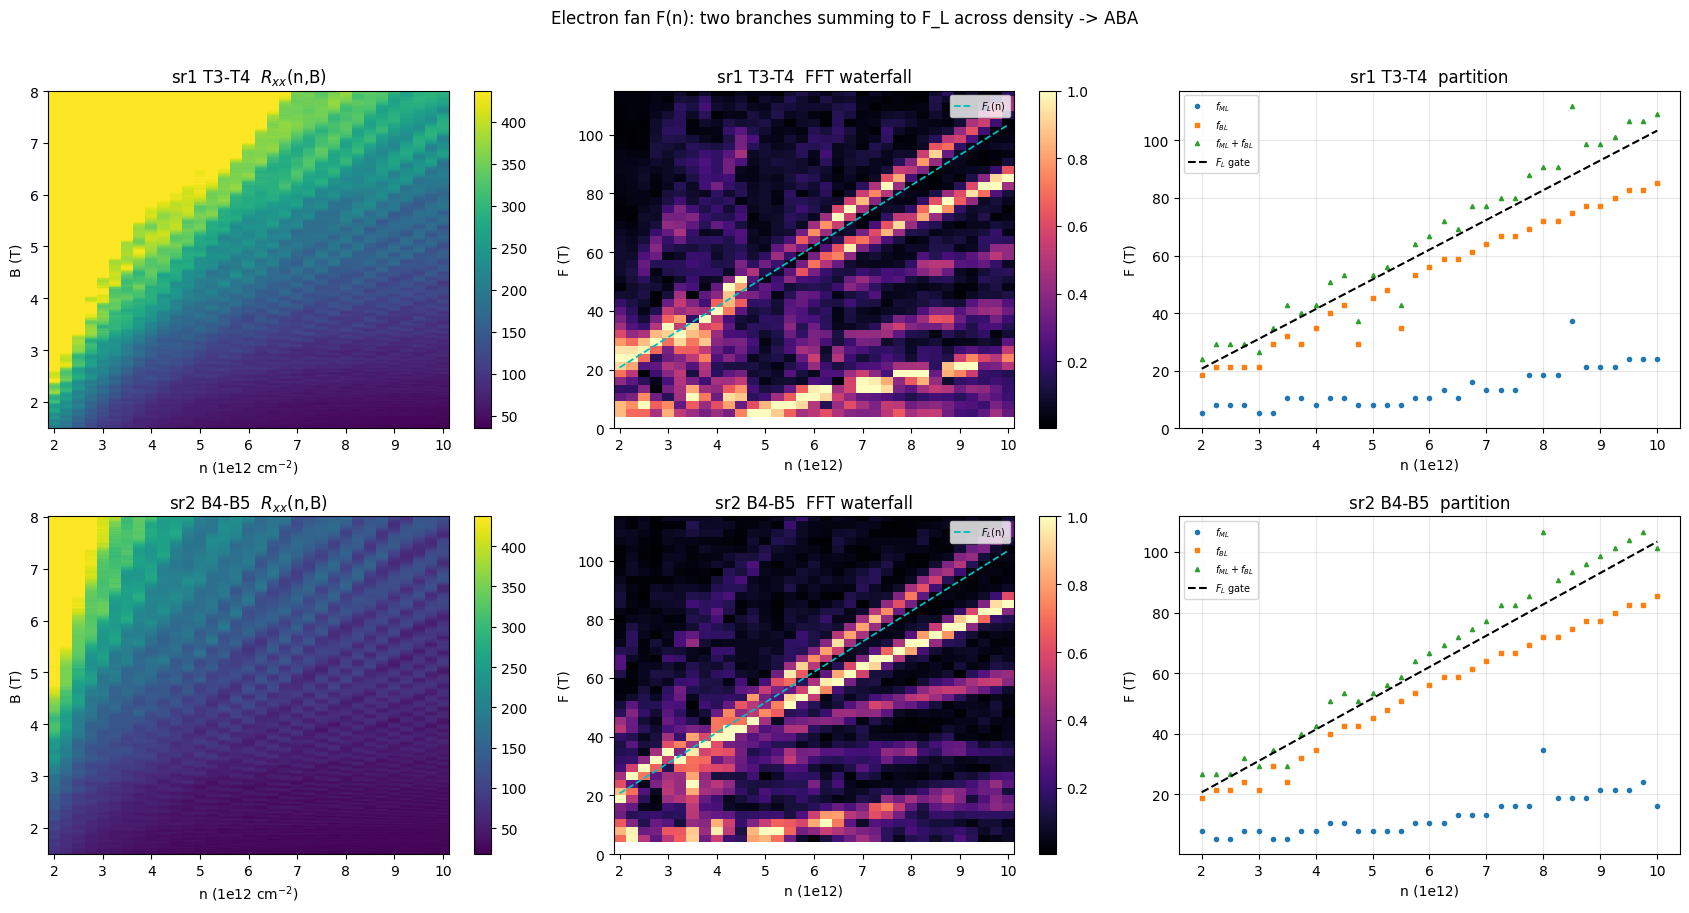

lambda~1.06-1.08 CONSTANT across n => f_ML+f_BL=F_L robust => two Fermi surfaces => ABA.
lambda is the SdH lever-arm; agrees with the Hall n-scale (n_H/n_gate~1.05-1.07).


In [8]:
# Electron Landau fan (run 6): per-column SdH FFT -> F(n) -> partition-robustness test.
# The model-independent FS-count refinement: f_ML(n)+f_BL(n)=lambda*F_L(n), lambda const
# across n => two Fermi surfaces => ABA. lambda is also the SdH-based lever-arm (n-scale).
from hera.analysis import sdh_fft, luttinger_frequency

mF = load_meta(6); ciF = {c: i for i, c in enumerate(mF['columns'])}
rawF = np.loadtxt(os.path.join(file_path, '6', 'data.tsv.gz'))
IbF = mF['measurement_config']['bias_voltage'] / mF['measurement_config']['bias_resistor']
nsF = np.linspace(2e12, 10e12, 33); NNf = len(nsF); NBf = len(rawF)//NNf
BvalsF = rawF[:NBf*NNf, ciF['magnet_mag']].reshape(NBf, NNf)[:, 0]
FLgF = luttinger_frequency(nsF*1e4)
def gridF(c): return (rawF[:NBf*NNf, ciF[c]]/IbF).reshape(NBf, NNf)
RF = {'sr1 T3-T4': gridF('sr1_X'), 'sr2 B4-B5': gridF('sr2_X')}
OVLf = 430.0

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for row, (nm, Rg) in enumerate(RF.items()):
    f, spec = sdh_fft(Rg, BvalsF, b_range=(2.0, 8.0), detrend=5, window='hann', nfft=4096, log=False)
    fML = np.full(NNf, np.nan); fBL = np.full(NNf, np.nan); clip = np.zeros(NNf, bool)
    for j in range(NNf):
        clip[j] = (Rg[BvalsF > 4, j] > OVLf).mean() > 0.1
        S = spec[j]; FL = FLgF[j]
        lo = (f > 0.12*FL) & (f < 0.45*FL); hi = (f > 0.55*FL) & (f < 0.92*FL)
        if lo.any() and S[lo].max() > 0.12*S.max(): fML[j] = f[lo][np.argmax(S[lo])]
        if hi.any() and S[hi].max() > 0.12*S.max(): fBL[j] = f[hi][np.argmax(S[hi])]
    fb = (f > 4) & (f < 120)
    a = axes[row, 0]; im = a.pcolormesh(nsF/1e12, BvalsF, np.clip(Rg, 0, 450), shading='auto', cmap='viridis')
    a.set_xlabel('n (1e12 cm$^{-2}$)'); a.set_ylabel('B (T)'); a.set_title(f'{nm}  $R_{{xx}}$(n,B)'); plt.colorbar(im, ax=a)
    a = axes[row, 1]; Sn = spec[:, fb]/spec[:, fb].max(axis=1, keepdims=True)
    im = a.pcolormesh(nsF/1e12, f[fb], Sn.T, shading='auto', cmap='magma'); plt.colorbar(im, ax=a)
    a.plot(nsF/1e12, FLgF, 'c--', lw=1.3, label='$F_L$(n)'); a.set_ylim(0, 115)
    a.set_xlabel('n (1e12)'); a.set_ylabel('F (T)'); a.set_title(f'{nm}  FFT waterfall'); a.legend(fontsize=7)
    a = axes[row, 2]; good = np.isfinite(fML) & np.isfinite(fBL) & ~clip
    a.plot(nsF/1e12, fML, 'o', ms=3, label='$f_{ML}$'); a.plot(nsF/1e12, fBL, 's', ms=3, label='$f_{BL}$')
    a.plot(nsF/1e12, fML+fBL, '^', ms=3, label='$f_{ML}+f_{BL}$'); a.plot(nsF/1e12, FLgF, 'k--', label='$F_L$ gate')
    a.set_xlabel('n (1e12)'); a.set_ylabel('F (T)'); a.set_title(f'{nm}  partition'); a.legend(fontsize=7); a.grid(alpha=.3)
    if good.sum() >= 4:
        lam = ((fML+fBL)/FLgF)[good]
        print(f'[{nm}] {good.sum()}/{NNf} good cols (clipped {clip.sum()}): '
              f'lambda=(f_ML+f_BL)/F_L = {lam.mean():.3f}+/-{lam.std():.3f}; '
              f'f_BL/F_L={np.nanmean((fBL/FLgF)[good]):.2f}, f_ML/F_L={np.nanmean((fML/FLgF)[good]):.2f}')
plt.suptitle('Electron fan F(n): two branches summing to F_L across density -> ABA', y=1.01)
plt.tight_layout(); plt.show()
print('lambda~1.06-1.08 CONSTANT across n => f_ML+f_BL=F_L robust => two Fermi surfaces => ABA.')
print('lambda is the SdH lever-arm; agrees with the Hall n-scale (n_H/n_gate~1.05-1.07).')


# STACKING CALL — QC0426 trilayer graphene: **ABA (Bernal)**, strong

*Independent FS-count determination per `investigations/trilayer-stacking-fs-count.md`,
from this session's data only (strict isolation; no prior-campaign input). Output
contract, all five parts.*

## 1. Per-region verdict (strength scale)

- **sr1 / pair T3–T4 (top arc): ABA (strong).** Two-tone partition resolved at
  n=±8e12 (spot checks, runs 4/5) and tracked across the fan (run 6, 15/33 columns;
  18 low-n columns excluded for high-B overload). λ ≡ (f_ML+f_BL)/F_L = 1.083 ± 0.055.
- **sr2 / pair B4–B5 (bottom): ABA (strong).** Partition robust across 29/33 fan
  columns; λ = 1.056 ± 0.074; corroborated by both spot checks.
- **Device-level: ABA, both probed regions agree — no stacking mosaic detected.**
  sr1 and sr2 give the *same* partition (f_BL/F_L ≈ 0.85, f_ML/F_L ≈ 0.20) → single
  stacking across the contacted area. Rxy (Hall pair T5–B6) provided the consistent
  density cross-check.

## 2. Evidence (frequencies, coordinates, Luttinger check)

- **f_BL ≈ 0.85·F_L — bilayer-like (quadratic) pocket.** n=+8e12,D=0: 70 T (sr1),
  69 T (sr2); n=−8e12,D=0: 72 T both. Tracks ∝n across the fan. Detrender-robust
  (poly 3/5/7 × hann/blackman).
- **f_ML ≈ 0.20·F_L — monolayer-like (Dirac) pocket** (the discriminating small
  partner). n=+8e12: 16 T (sr1), 19 T (sr2); n=−8e12: 16 T both. Detrender-robust;
  mildly window-sensitive (the known f_ML extraction fork).
- **Luttinger sum (the decisive FS-count evidence):** f_ML+f_BL = λ·F_L with
  λ = 1.06–1.08 **constant across density** in both channels (fan), and λ matches
  the Hall-slope rescale (n_H/n_gate = 1.05–1.07). Model-independent, robust across n
  → **two Fermi surfaces**, not one.
- **Onsager forward-model overlay: NOT performed at the operating density** — the
  model (`fs_count_b0`) clamps F(n) above |n|≈3.5e12, below the ±8e12 operating point
  (model README). ML/BL labeling is by pocket size + band-structure expectation, not
  curve shape.
- **Coverage:** 4 fixed-density spot checks (2 channels × hole/electron) + a 33-column
  electron fan, all showing the pair. **No measurement showed a single tone at F_L**
  (the ABC signature).

## 3. Confidence + hedges

**Binary ABA-vs-ABC: confident (ABA).** The investigation's binary criterion —
partition robustness, model-independent — is satisfied across density, both channels,
both sides. ABC is excluded (the small ML partner is resolved and robust).

Hedges (why "strong", not "decisive"):
- **LK effective-mass split NOT measured** — the gold-standard two-band confirmation
  and rigorous beat exclusion (`temperature-dependence`, **blocklisted** this session).
  Beat exclusion here rests on the FFT/partition argument (a beat would not yield an
  independent f_ML∝n branch satisfying f_ML+f_BL=F_L across density) — strong, but not
  the decisive mass cross-check.
- **Onsager overlay unavailable** at operating density (model clamp) — ML/BL by size.
- **Low-n columns clipped** at high B (sr1 18/33, sr2 4/33) from the climbing MR; the
  partition rests on the unclipped mid-/high-n columns (sr2: 29).
- **Warm rig** (base ≈1.2 K, T_e ≈8 K): the count is at the resolvable level; no claim
  about features *absent* at this T (those are "unresolved, not absent").
- **n-scale:** absolute n carried a ~7% geometry-prior error, now upgraded via the SdH
  lever-arm (λ) and the Hall slope (two independent, agreeing).

## 4. What would firm / extend

- **LK mass split** (`temperature-dependence` Flavor B) — the decisive ML-light /
  BL-heavy two-mass confirmation + beat exclusion. (Blocklisted this session; the
  natural next step.)
- **Onsager overlay** once the `fs_count_b0` clamp is extended past 8e12 (model TODO).
- **Lower T / higher mobility (mK rig)** — sharpens the small ML tone for any ABA
  QHF / interaction follow-up.

## 5. Bottom line

**QC0426 is ABA (Bernal) trilayer graphene — strong, both probed regions (T3–T4,
B4–B5), both density sides.** Two coexisting Fermi surfaces (ML Dirac + BL parabolic)
partition the Luttinger density robustly across n; ABC is excluded. The one cross-check
short of "decisive" — the LK mass split — was blocklisted this session and is the
recommended next step. This is a confident call backed by feature-level evidence (the
required standard), not a bare lean.

**Campaign implication (`fs-count` Next):** ABA-confirmed → conventional trilayer; the
correlated/flat-band physics lives on the ABC side, so the high-value QHF/interaction
follow-up needs lower T and higher mobility (an mK rig). Deprioritize on the VTI unless
the QHF angle is pursued.

*Evidence in this notebook: spot A (cell 15), spot B (cell 17), fan F(n) (cell 19);
calibration (cells 12–13). Raw runs: data/4 (e spot), data/5 (h spot), data/6 (fan);
data/2 (gate map). Acquisition/QA log: session_notes.md.*
